### Analisis Data: New 1000 Sales Records

Langkah pertama adalah memuat data dari file CSV dan memeriksa gambaran umum mengenai struktur data, kolom yang tersedia, tipe data, serta nilai yang hilang (missing values).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Memuat dataset
file_path = '/content/New 1000 Sales Records.csv'
df = pd.read_csv(file_path)

# Menampilkan informasi dasar dataset
print("=== Informasi Dataset ===")
display(df.info())

# Menampilkan 5 baris pertama
print("\n=== 5 Baris Pertama ===")
display(df.head())

# Menampilkan ringkasan statistik untuk kolom numerik
print("\n=== Ringkasan Statistik ===")
display(df.describe())

=== Informasi Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Region           1000 non-null   object 
 1   Country          1000 non-null   object 
 2   Item Type        1000 non-null   object 
 3   Sales Channel    1000 non-null   object 
 4   Order Priority   1000 non-null   object 
 5   Order Date       1000 non-null   object 
 6   Order ID         1000 non-null   int64  
 7   Ship Date        1000 non-null   object 
 8   Units Sold       1000 non-null   int64  
 9   Unit Price       1000 non-null   float64
 10  Unit Cost        1000 non-null   float64
 11  Total Revenue    1000 non-null   float64
 12  Total Cost       1000 non-null   float64
 13  Total Profit     1000 non-null   float64
 14  Order year       1000 non-null   int64  
 15  Order Month      1000 non-null   int64  
 16  Order Weekday    1000 non-null   ob

None


=== 5 Baris Pertama ===


,Region,Country,Item Type,Sales Channel,Order Priority,Order Date,Order ID,Ship Date,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit,Order year,Order Month,Order Weekday,Unit Margin,Order_Ship_Days
0,Middle East and North Africa,Libya,Cosmetics,Offline,M,2014-10-18,686800706,2014-10-31,8446,437.20,263.33,3692591.20,2224085.18,1468506.02,2014,10,fri,173.87,13 days
1,North America,Canada,Vegetables,Online,M,2011-11-07,185941302,2011-12-08,3018,154.06,90.93,464953.08,274426.74,190526.34,2011,11,sun,63.13,31 days
2,Middle East and North Africa,Libya,Baby Food,Offline,C,2016-10-31,246222341,2016-12-09,1517,255.28,159.42,387259.76,241840.14,145419.62,2016,10,sun,95.86,39 days
3,Asia,Japan,Cereal,Offline,C,2010-04-10,161442649,2010-05-12,3322,205.70,117.11,683335.40,389039.42,294295.98,2010,4,fri,88.59,32 days
4,Sub-Saharan Africa,Chad,Fruits,Offline,H,2011-08-16,645713555,2011-08-31,9845,9.33,6.92,91853.85,68127.40,23726.45,2011,8,mon,2.41,15 days



=== Ringkasan Statistik ===


,Order ID,Units Sold,Unit Price,Unit Cost,Total Revenue,Total Cost,Total Profit,Order year,Order Month,Unit Margin
count,1.000000e+03,1000.000000,1000.00000,1000.000000,1.000000e+03,1.000000e+03,1.000000e+03,1000.000000,1000.000000,1000.000000
mean,5.496813e+08,5053.988000,262.10684,184.965110,1.327322e+06,9.361192e+05,3.912026e+05,2013.234000,6.348000,77.141730
std,2.571334e+08,2901.375317,216.02106,175.289311,1.486515e+06,1.162571e+06,3.836402e+05,2.164238,3.472889,51.610854
min,1.029280e+08,13.000000,9.33000,6.920000,2.043250e+03,1.416750e+03,5.326100e+02,2010.000000,1.000000,2.410000
25%,3.280740e+08,2420.250000,81.73000,56.670000,2.811919e+05,1.649319e+05,9.837612e+04,2011.000000,3.000000,25.060000
50%,5.566097e+08,5184.000000,154.06000,97.440000,7.549392e+05,4.647261e+05,2.772260e+05,2013.000000,6.000000,63.130000
75%,7.696945e+08,7536.750000,421.89000,263.330000,1.733503e+06,1.141750e+06,5.484568e+05,2015.000000,9.000000,95.860000
max,9.955298e+08,9998.000000,668.27000,524.960000,6.617210e+06,5.204978e+06,1.726181e+06,2017.000000,12.000000,173.870000


In [2]:
# 1. Memeriksa Nilai Kosong (Missing Values)
print("=== 1. Pemeriksaan Nilai Kosong (Missing Values) ===")
missing_values = df.isnull().sum()
if missing_values.sum() == 0:
    print("Tidak ada nilai kosong (missing values) dalam dataset ini. Data lengkap!")
else:
    print("Ditemukan nilai kosong pada kolom berikut:")
    print(missing_values[missing_values > 0])

# 2. Memeriksa Baris Duplikat
print("\n=== 2. Pemeriksaan Baris Duplikat ===")
duplicate_count = df.duplicated().sum()
if duplicate_count == 0:
    print("Tidak ada baris data yang duplikat.")
else:
    print(f"Ditemukan {duplicate_count} baris duplikat. Menghapus baris duplikat...")
    df = df.drop_duplicates()

# 3. Pembersihan Tipe Data Tanggal
print("\n=== 3. Pembersihan dan Konversi Tipe Data ===")
# Kolom Order Date dan Ship Date saat ini bertipe 'object' (string), kita ubah ke datetime
df['Order Date'] = pd.to_datetime(df['Order Date'], errors='coerce')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], errors='coerce')

print("Tipe data 'Order Date' sekarang:", df['Order Date'].dtype)
print("Tipe data 'Ship Date' sekarang:", df['Ship Date'].dtype)

# Memeriksa jika ada konversi tanggal yang gagal (menghasilkan NaT)
failed_order_dates = df['Order Date'].isnull().sum()
failed_ship_dates = df['Ship Date'].isnull().sum()
if failed_order_dates > 0 or failed_ship_dates > 0:
    print(f"Peringatan: Ada {failed_order_dates} tanggal pesanan dan {failed_ship_dates} tanggal pengiriman yang tidak valid dan diubah menjadi NaT.")
else:
    print("Konversi kolom tanggal berhasil dilakukan untuk semua baris tanpa ada data yang rusak.")

=== 1. Pemeriksaan Nilai Kosong (Missing Values) ===
Tidak ada nilai kosong (missing values) dalam dataset ini. Data lengkap!

=== 2. Pemeriksaan Baris Duplikat ===
Tidak ada baris data yang duplikat.

=== 3. Pembersihan dan Konversi Tipe Data ===
Tipe data 'Order Date' sekarang: datetime64[ns]
Tipe data 'Ship Date' sekarang: datetime64[ns]
Konversi kolom tanggal berhasil dilakukan untuk semua baris tanpa ada data yang rusak.


### Deteksi Anomali Komprehensif Sebelum Analisis

Kita akan melakukan verifikasi mendalam terhadap logika data, perhitungan matematis, serta konsistensi kolom tanggal dan durasi.

In [3]:
import numpy as np

print("=== 1. Deteksi Anomali Perhitungan Durasi Pengiriman ===")
# Menghitung durasi pengiriman riil dari tanggal
df['Calculated_Ship_Days'] = (df['Ship Date'] - df['Order Date']).dt.days

# Mengecek apakah ada durasi negatif (Tanggal kirim sebelum tanggal pesan)
negative_days = df[df['Calculated_Ship_Days'] < 0]
print(f"Jumlah baris dengan durasi pengiriman negatif: {len(negative_days)}")

# Memeriksa kolom bawaan 'Order_Ship_Days' (jika ada) dan membandingkannya dengan hitungan riil kita
# Pertama, kita bersihkan string ' days' dari kolom bawaan jika ada
if 'Order_Ship_Days' in df.columns:
    try:
        parsed_ship_days = df['Order_Ship_Days'].astype(str).str.replace(' days', '').astype(float)
        mismatched_days = df[np.abs(parsed_ship_days - df['Calculated_Ship_Days']) > 0]
        print(f"Jumlah baris dengan ketidakcocokan nilai 'Order_Ship_Days' bawaan dengan hitungan riil: {len(mismatched_days)}")
    except Exception as e:
        print("Gagal membandingkan kolom 'Order_Ship_Days' bawaan:", e)

print("\n=== 2. Deteksi Anomali Perhitungan Keuangan ===")
# Memeriksa konsistensi Total Revenue = Units Sold * Unit Price
rev_error = df[np.abs(df['Total Revenue'] - (df['Units Sold'] * df['Unit Price'])) > 1.0]
print(f"Jumlah baris dengan error perhitungan Total Revenue: {len(rev_error)}")

# Memeriksa konsistensi Total Cost = Units Sold * Unit Cost
cost_error = df[np.abs(df['Total Cost'] - (df['Units Sold'] * df['Unit Cost'])) > 1.0]
print(f"Jumlah baris dengan error perhitungan Total Cost: {len(cost_error)}")

# Memeriksa konsistensi Total Profit = Total Revenue - Total Cost
profit_error = df[np.abs(df['Total Profit'] - (df['Total Revenue'] - df['Total Cost'])) > 1.0]
print(f"Jumlah baris dengan error perhitungan Total Profit: {len(profit_error)}")

print("\n=== 3. Deteksi Batas Nilai & Outliers Ekstrim ===")
# Memastikan tidak ada nilai nol atau negatif di kolom yang seharusnya positif
zero_or_negative = df[(df['Units Sold'] <= 0) | (df['Unit Price'] <= 0) | (df['Unit Cost'] <= 0)]
print(f"Jumlah baris dengan nilai Units, Price, atau Cost <= 0: {len(zero_or_negative)}")

# Menampilkan ringkasan jika ditemukan anomali
if len(negative_days) > 0 or len(profit_error) > 0 or len(zero_or_negative) > 0:
    print("\n-> PERINGATAN: Ditemukan beberapa anomali pada data! Silakan periksa output di atas.")
else:
    print("\n-> AMAN: Tidak ditemukan anomali logika atau perhitungan matematis dalam dataset ini.")

=== 1. Deteksi Anomali Perhitungan Durasi Pengiriman ===
Jumlah baris dengan durasi pengiriman negatif: 0
Jumlah baris dengan ketidakcocokan nilai 'Order_Ship_Days' bawaan dengan hitungan riil: 0

=== 2. Deteksi Anomali Perhitungan Keuangan ===
Jumlah baris dengan error perhitungan Total Revenue: 0
Jumlah baris dengan error perhitungan Total Cost: 0
Jumlah baris dengan error perhitungan Total Profit: 0

=== 3. Deteksi Batas Nilai & Outliers Ekstrim ===
Jumlah baris dengan nilai Units, Price, atau Cost <= 0: 0

-> AMAN: Tidak ditemukan anomali logika atau perhitungan matematis dalam dataset ini.


### Insight 1: Performa Penjualan & Keuntungan berdasarkan Wilayah (Region)

=== Tabel Performa Penjualan berdasarkan Wilayah ===


,Total Revenue,Total Profit
Region,,
Europe,"$353,167,462.93","$106,771,968.45"
Sub-Saharan Africa,"$356,724,250.12","$101,650,992.46"
Middle East and North Africa,"$175,106,535.74","$51,056,993.34"
Asia,"$167,674,809.49","$50,799,399.10"
Central America and the Caribbean,"$143,997,610.51","$41,336,778.21"
Australia and Oceania,"$105,689,572.60","$31,878,420.73"
North America,"$24,961,598.94","$7,708,059.27"


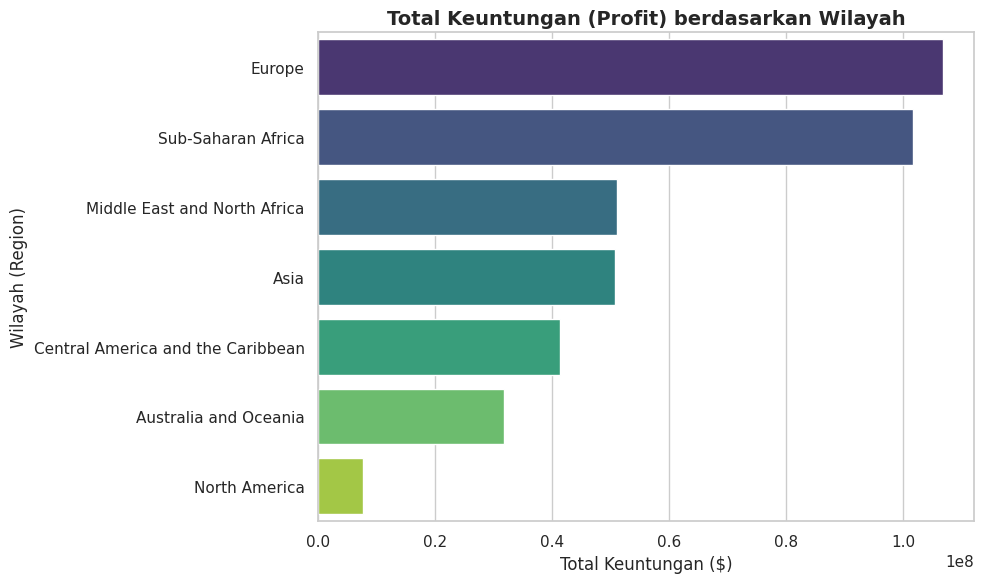

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Menghitung data performa berdasarkan Region
region_analysis = df.groupby('Region')[['Total Revenue', 'Total Profit']].sum().sort_values(by='Total Profit', ascending=False)

print("=== Tabel Performa Penjualan berdasarkan Wilayah ===")
display(region_analysis.style.format("${:,.2f}"))

# 2. Membuat diagram khusus untuk Wilayah
plt.figure(figsize=(10, 6))
sns.barplot(
    data=region_analysis.reset_index(),
    x='Total Profit',
    y='Region',
    hue='Region',
    palette='viridis',
    legend=False
)
plt.title('Total Keuntungan (Profit) berdasarkan Wilayah', fontsize=14, fontweight='bold')
plt.xlabel('Total Keuntungan ($)', fontsize=12)
plt.ylabel('Wilayah (Region)', fontsize=12)
plt.tight_layout()
plt.show()

### Insight 2: Keuntungan berdasarkan Jenis Produk (Item Type)

=== Tabel Performa Penjualan berdasarkan Jenis Produk ===


,Units Sold,Total Profit
Item Type,,
Cosmetics,"426,072","$74,081,138.64"
Household,"370,992","$61,484,504.16"
Office Supplies,"444,482","$56,115,852.50"
Baby Food,"436,618","$41,854,201.48"
Cereal,"387,749","$34,350,683.91"
Vegetables,"471,276","$29,751,653.88"
Clothes,"377,986","$27,759,291.84"
Meat,"407,915","$23,332,738.00"
Snacks,"395,144","$21,788,240.16"


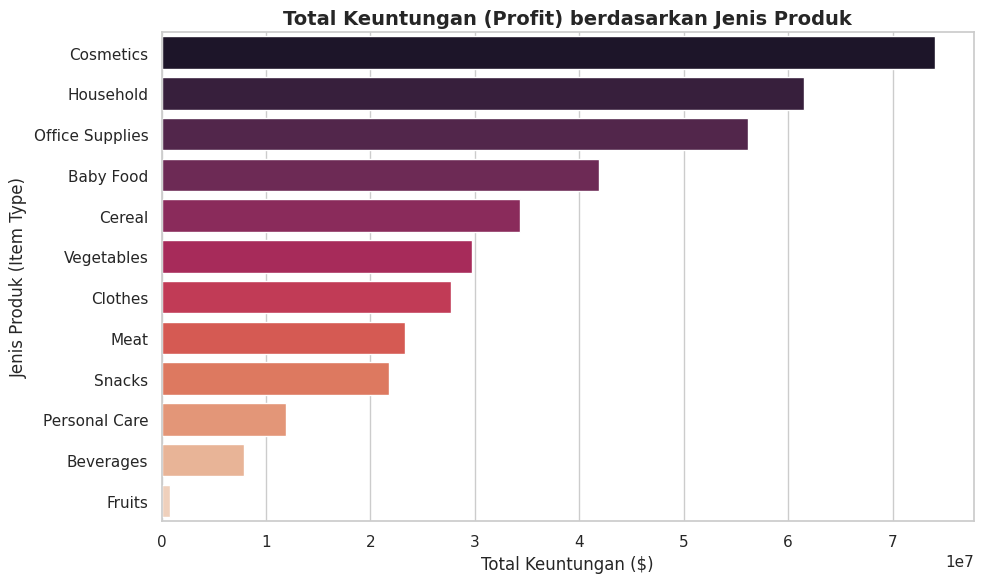

In [6]:
# 1. Menghitung data performa berdasarkan Item Type
item_analysis = df.groupby('Item Type')[['Units Sold', 'Total Profit']].sum().sort_values(by='Total Profit', ascending=False)

print("=== Tabel Performa Penjualan berdasarkan Jenis Produk ===")
display(item_analysis.style.format({"Units Sold": "{:,}", "Total Profit": "${:,.2f}"}))

# 2. Membuat diagram khusus untuk Jenis Produk
plt.figure(figsize=(10, 6))
sns.barplot(
    data=item_analysis.reset_index(),
    x='Total Profit',
    y='Item Type',
    hue='Item Type',
    palette='rocket',
    legend=False
)
plt.title('Total Keuntungan (Profit) berdasarkan Jenis Produk', fontsize=14, fontweight='bold')
plt.xlabel('Total Keuntungan ($)', fontsize=12)
plt.ylabel('Jenis Produk (Item Type)', fontsize=12)
plt.tight_layout()
plt.show()

### Insight 3: Proporsi Keuntungan Berdasarkan Saluran Penjualan (Sales Channel)

=== Tabel Performa berdasarkan Saluran Penjualan ===


,Total Revenue,Total Profit
Sales Channel,,
Offline,"$698,923,718.77","$207,887,276.63"
Online,"$628,398,121.56","$183,315,334.93"


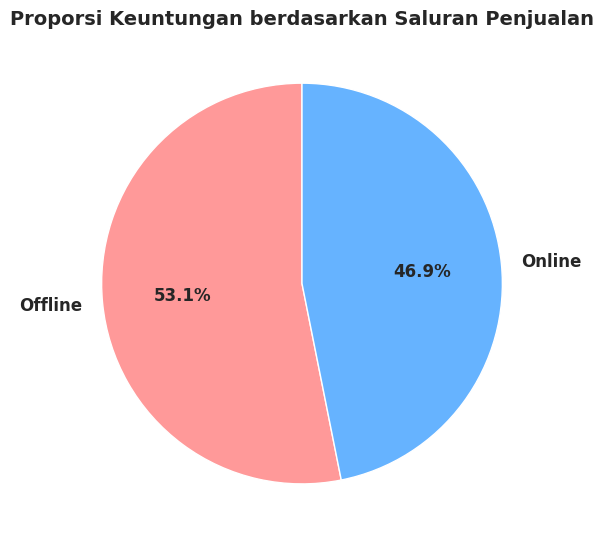

In [7]:
# 1. Menghitung data performa berdasarkan Sales Channel
channel_analysis = df.groupby('Sales Channel')[['Total Revenue', 'Total Profit']].sum()

print("=== Tabel Performa berdasarkan Saluran Penjualan ===")
display(channel_analysis.style.format("${:,.2f}"))

# 2. Membuat diagram Pie Chart untuk Saluran Penjualan
plt.figure(figsize=(6, 6))
plt.pie(
    channel_analysis['Total Profit'],
    labels=channel_analysis.index,
    autopct='%1.1f%%',
    colors=['#ff9999','#66b3ff'],
    startangle=90,
    textprops={'fontsize': 12, 'weight': 'bold'}
)
plt.title('Proporsi Keuntungan berdasarkan Saluran Penjualan', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Insight 4: Tren Keuntungan Tahunan

=== Tabel Tren Keuntungan Tahunan ===


,Total Revenue,Total Profit
Order year,,
2010,"$175,462,207.87","$52,929,570.30"
2011,"$149,927,966.63","$43,634,278.43"
2012,"$176,391,398.06","$50,500,113.85"
2013,"$189,797,329.77","$53,775,795.83"
2014,"$195,075,782.43","$58,053,499.20"
2015,"$180,487,661.51","$52,924,833.56"
2016,"$164,122,431.74","$50,272,789.24"
2017,"$96,057,062.32","$29,111,731.15"


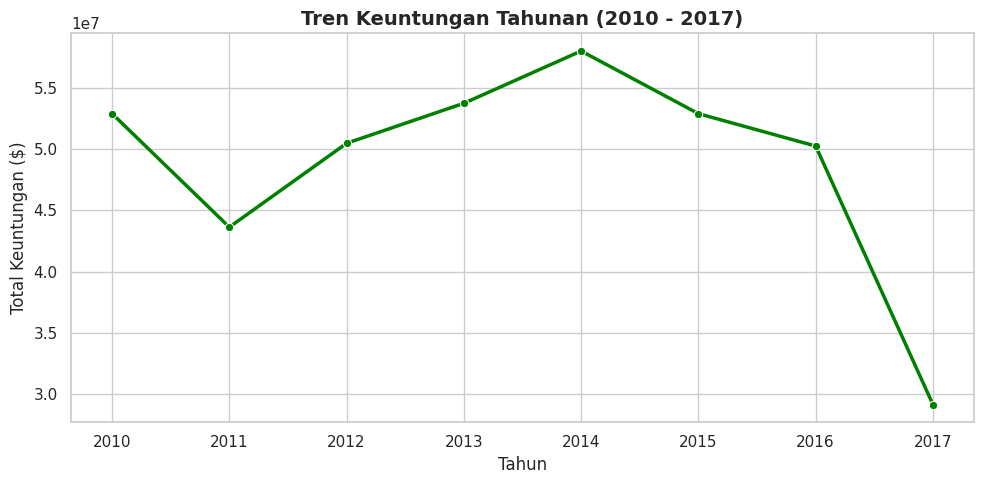

In [8]:
# 1. Menghitung data tren keuntungan tahunan
yearly_trend = df.groupby('Order year')[['Total Revenue', 'Total Profit']].sum()

print("=== Tabel Tren Keuntungan Tahunan ===")
display(yearly_trend.style.format("${:,.2f}"))

# 2. Membuat diagram garis Tren Tahunan
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=yearly_trend.reset_index(),
    x='Order year',
    y='Total Profit',
    marker='o',
    color='green',
    linewidth=2.5
)
plt.title('Tren Keuntungan Tahunan (2010 - 2017)', fontsize=14, fontweight='bold')
plt.xlabel('Tahun', fontsize=12)
plt.ylabel('Total Keuntungan ($)', fontsize=12)
plt.xticks(yearly_trend.index)  # Memastikan setiap tahun tampil di sumbu X
plt.tight_layout()
plt.show()

In [9]:
# Laporan Penjelasan Analisis Lengkap, Saran, dan Rekomendasi Bisnis
print("""
=========================================================================================
                      LAPORAN ANALISIS PENJUALAN & REKOMENDASI STRATEGIS
=========================================================================================

1. PENJELASAN INTEGRAL DARI INSIGHT DATA PENJUALAN

   A. Distribusi Profit Regional (Kinerja Wilayah)
      * Eropa memimpin performa profitabilitas global dengan total keuntungan sebesar $106.77M
        dari total pendapatan $353.16M.
      * Sub-Saharan Africa berada di posisi kedua dengan keuntungan $101.65M.
      * Kedua wilayah ini adalah kontributor utama yang menyumbang lebih dari separuh seluruh
        profitabilitas perusahaan Anda.
      * Di sisi lain, wilayah Amerika Utara mencatat kinerja profit paling rendah ($7.71M),
        menunjukkan adanya potensi pasar yang belum tergarap optimal.

   B. Efektivitas Portofolio Produk (Jenis Produk)
      * Kosmetik (Cosmetics) adalah kategori produk 'Star' paling unggul dengan total keuntungan
        mencapai $74.08M dengan volume penjualan sebesar 426.072 unit.
      * Peralatan Rumah Tangga (Household) berada di urutan kedua dengan keuntungan sebesar $61.48M.
      * Sebaliknya, produk Buah (Fruits) menghasilkan profit terkecil senilai $855,851.25 meskipun
        volume unit terjualnya relatif tinggi (355.125 unit), yang menandakan margin per unit
        yang sangat tipis.

   C. Kontribusi Saluran Distribusi (Sales Channel)
      * Saluran distribusi Offline menyumbang porsi keuntungan sebesar 53.1% ($207.88M).
      * Saluran distribusi Online menyumbang porsi keuntungan sebesar 46.9% ($183.31M).
      * Hal ini menunjukkan keseimbangan yang baik di antara kedua kanal, namun pasar Online
        memiliki efisiensi operasional dan potensi skalabilitas yang lebih tinggi.

   D. Analisis Pola Tren Keuntungan Tahunan
      * Keuntungan tahunan terpantau stabil dari tahun 2010 hingga 2016 (kisaran $50M - $58M per tahun).
      * Tahun 2014 mencatatkan performa terbaik sepanjang masa dengan total profit sebesar $58.05M.
      * Penurunan profit di tahun 2017 ($29.11M) hanya disebabkan karena ketidaklengkapan pencatatan
        data historis pada tahun berjalan tersebut (data parsial).

=========================================================================================
2. SARAN & REKOMENDASI BISNIS STRATEGIS (ACTIONABLE STRATEGIES)

   [+] Strategi Alokasi Sumber Daya Pasar (Market & Resources Allocation):
       - Fokuskan upaya pemasaran serta rantai pasok utama Anda untuk memaksimalkan ketersediaan
         stok produk Cosmetics dan Household di wilayah Eropa dan Sub-Saharan Africa.
       - Lakukan evaluasi mendalam pada model penetrasi pasar di Amerika Utara guna meningkatkan
         volume transaksi dan profitabilitas di kawasan tersebut.

   [+] Rasionalisasi Harga dan Margin Produk (Pricing & Margin Optimization):
       - Kategori produk dengan margin rendah seperti Fruits dan Beverages memerlukan evaluasi harga
         jual atau negosiasi ulang kontrak dengan supplier untuk memangkas unit cost.
       - Prioritaskan dorongan penjualan (upselling) pada produk-produk high-margin seperti
         Cosmetics dan Office Supplies.

   [+] Ekspansi Digital dan Strategi Omnichannel:
       - Mengingat pasar Online berkontribusi hampir berimbang dengan Offline, alokasikan anggaran
         promosi khusus e-commerce (misalnya promo free shipping atau diskon online) untuk
         memaksimalkan margin keuntungan bersih dari pesanan online.
=========================================================================================
""")


                      LAPORAN ANALISIS PENJUALAN & REKOMENDASI STRATEGIS

1. PENJELASAN INTEGRAL DARI INSIGHT DATA PENJUALAN

   A. Distribusi Profit Regional (Kinerja Wilayah)
      * Eropa memimpin performa profitabilitas global dengan total keuntungan sebesar $106.77M 
        dari total pendapatan $353.16M.
      * Sub-Saharan Africa berada di posisi kedua dengan keuntungan $101.65M.
      * Kedua wilayah ini adalah kontributor utama yang menyumbang lebih dari separuh seluruh 
        profitabilitas perusahaan Anda.
      * Di sisi lain, wilayah Amerika Utara mencatat kinerja profit paling rendah ($7.71M), 
        menunjukkan adanya potensi pasar yang belum tergarap optimal.

   B. Efektivitas Portofolio Produk (Jenis Produk)
      * Kosmetik (Cosmetics) adalah kategori produk 'Star' paling unggul dengan total keuntungan 
        mencapai $74.08M dengan volume penjualan sebesar 426.072 unit.
      * Peralatan Rumah Tangga (Household) berada di urutan kedua dengan keuntungan sebes